# Analyse de sentiment IMDB : BiLSTM vs BiGRU

Classification binaire (positif / négatif) de **50 000 avis IMDB** avec deux réseaux récurrents bidirectionnels
(LSTM et GRU) alimentés par des embeddings **GloVe 100d**. Ce notebook sert de **référence (baseline)** pour la
comparaison avec le fine-tuning de BERT (`02_bert_finetuning.ipynb`).

**Principes de la comparaison**
- Même découpage 80 / 10 / 10 que le notebook BERT (l'empreinte du jeu de test s'affiche dans les deux).
- LSTM et GRU ont **exactement la même configuration** (1 couche, bidirectionnels, mêmes hyperparamètres).
- Les séquences sont traitées avec `pack_padded_sequence` : le réseau ne lit pas le rembourrage (padding).
- Sélection du meilleur modèle par la perte de validation (early stopping) ; le jeu de test n'est utilisé qu'une fois.

**Exécution :** Colab → *Exécution → Modifier le type d'exécution → GPU (T4)*, puis *Tout exécuter*. Durée : environ 10 à 20 minutes.

In [2]:
!pip install -q datasets scikit-learn matplotlib requests

In [3]:
import copy
import hashlib
import json
import os
import platform
import random
import re
import string
import time
import zipfile
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (un GPU est recommandé)")

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

Device : cuda | Tesla T4


## 1. Données

In [4]:
from datasets import load_dataset


def load_imdb():
    """IMDB : 25 000 avis d'entraînement + 25 000 de test = 50 000 avis équilibrés."""
    ds = load_dataset("stanfordnlp/imdb")
    df = pd.concat([ds["train"].to_pandas(), ds["test"].to_pandas()], ignore_index=True)
    df = df.rename(columns={"text": "review"})
    return df[["review", "label"]]  # label : 0 = négatif, 1 = positif


df = load_imdb()
print("Nombre d'avis :", len(df))
print(df["label"].value_counts().rename({0: "négatifs", 1: "positifs"}))

Nombre d'avis : 50000
label
négatifs    25000
positifs    25000
Name: count, dtype: int64


In [5]:
# Exploration : taille, équilibre des classes, longueur des avis
MAX_LEN = 200  # nombre maximal de mots conservés par avis

lengths = df["review"].str.split().str.len()
print(f"Longueur moyenne : {lengths.mean():.1f} mots | médiane : {lengths.median():.0f} mots")
print(f"Avis plus longs que {MAX_LEN} mots (tronqués) : {(lengths > MAX_LEN).mean():.1%}")

for label, name in [(1, "positif"), (0, "négatif")]:
    print(f"\nExemple {name} :", df[df["label"] == label]["review"].iloc[0][:250].replace("<br />", " "), "...")

Longueur moyenne : 231.2 mots | médiane : 173 mots
Avis plus longs que 200 mots (tronqués) : 40.9%

Exemple positif : Zentropa has much in common with The Third Man, another noir-like film set among the rubble of postwar Europe. Like TTM, there is much inventive camera work. There is an innocent American who gets emotionally involved with a woman he doesn't really u ...

Exemple négatif : I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a  ...


In [6]:
from sklearn.model_selection import train_test_split
import hashlib

# Découpage stratifié 80 / 10 / 10. IDENTIQUE dans les deux notebooks (même graine, même code).
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED)

# Empreinte du jeu de test : doit être identique dans les deux notebooks.
SPLIT_FINGERPRINT = hashlib.md5("".join(test_df["review"].tolist()).encode("utf-8")).hexdigest()[:12]
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("Empreinte du jeu de test :", SPLIT_FINGERPRINT)

Train: 40000 | Val: 5000 | Test: 5000
Empreinte du jeu de test : f158b26f6f35


## 2. Prétraitement et vocabulaire

Mise en minuscules, suppression des balises HTML, des URLs, des chiffres et de la ponctuation, puis découpage en mots.
Le vocabulaire est construit **uniquement sur le jeu d'entraînement** (pas de fuite d'information) ; les mots vus moins de
`MIN_FREQ` fois sont remplacés par `<UNK>`.

In [7]:
def preprocess(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)               # balises HTML
    text = re.sub(r"http\S+|www\S+", "", text)       # URLs
    text = re.sub(r"\d+", "", text)                  # chiffres
    text = re.sub(f"[{re.escape(string.punctuation)}]", "", text)  # ponctuation
    return text.split()


sample = "I loved the movie! It was incredible. Visit http://example.com <br /> 10/10"
print("Avant :", sample)
print("Après :", preprocess(sample))

train_tokens = [preprocess(t) for t in train_df["review"]]
val_tokens = [preprocess(t) for t in val_df["review"]]
test_tokens = [preprocess(t) for t in test_df["review"]]

MIN_FREQ = 2
PAD_IDX, UNK_IDX = 0, 1
counts = Counter(tok for toks in train_tokens for tok in toks)
itos = ["<PAD>", "<UNK>"] + [w for w, c in counts.most_common() if c >= MIN_FREQ]
vocab = {w: i for i, w in enumerate(itos)}
print(f"Vocabulaire : {len(vocab)} mots (sur {len(counts)} mots distincts dans le train)")

Avant : I loved the movie! It was incredible. Visit http://example.com <br /> 10/10
Après : ['i', 'loved', 'the', 'movie', 'it', 'was', 'incredible', 'visit']
Vocabulaire : 66700 mots (sur 143989 mots distincts dans le train)


## 3. Embeddings GloVe

Vecteurs pré-entraînés **GloVe 6B 100d** (Stanford NLP). Le fichier (environ 820 Mo) est téléchargé une seule fois ;
les mots absents de GloVe sont initialisés aléatoirement.

In [8]:
GLOVE_URLS = [
    "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip",
    "https://nlp.stanford.edu/data/glove.6B.zip",
]
EMBED_DIM = 100


def download_glove(dest="glove"):
    path = os.path.join(dest, "glove.6B.100d.txt")
    if os.path.exists(path):
        return path
    os.makedirs(dest, exist_ok=True)
    zpath = os.path.join(dest, "glove.6B.zip")
    last_error = None
    for url in GLOVE_URLS:
        try:
            with requests.get(url, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(zpath, "wb") as f:
                    for chunk in r.iter_content(chunk_size=1 << 20):
                        f.write(chunk)
            break
        except Exception as exc:  # essaie l'URL suivante
            last_error = exc
    else:
        raise RuntimeError(f"Téléchargement de GloVe impossible : {last_error}")
    with zipfile.ZipFile(zpath) as z:
        z.extract("glove.6B.100d.txt", dest)
    os.remove(zpath)
    return path


def load_glove_vectors(path, vocab, embed_dim=EMBED_DIM):
    rng = np.random.RandomState(SEED)
    matrix = rng.uniform(-0.25, 0.25, (len(vocab), embed_dim)).astype("float32")
    matrix[PAD_IDX] = 0.0
    found = 0
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip().split(" ")
            idx = vocab.get(parts[0])
            if idx is not None and idx > UNK_IDX:
                matrix[idx] = np.asarray(parts[1:], dtype="float32")
                found += 1
    print(f"Mots du vocabulaire présents dans GloVe : {found}/{len(vocab) - 2} ({found / (len(vocab) - 2):.1%})")
    return torch.from_numpy(matrix)


embedding_matrix = load_glove_vectors(download_glove(), vocab)
print("Matrice d'embeddings :", tuple(embedding_matrix.shape))

Mots du vocabulaire présents dans GloVe : 53096/66698 (79.6%)
Matrice d'embeddings : (66700, 100)


## 4. Encodage et DataLoaders

Chaque avis devient une suite d'indices de longueur `MAX_LEN` (rembourrée à droite avec `<PAD>`). On conserve la **longueur
réelle** de chaque séquence pour que le réseau ignore le rembourrage.

In [9]:
def encode(tokens_list):
    X = np.zeros((len(tokens_list), MAX_LEN), dtype=np.int64)
    lengths = np.zeros(len(tokens_list), dtype=np.int64)
    for i, toks in enumerate(tokens_list):
        ids = [vocab.get(t, UNK_IDX) for t in toks[:MAX_LEN]] or [UNK_IDX]
        X[i, : len(ids)] = ids
        lengths[i] = len(ids)
    return torch.from_numpy(X), torch.from_numpy(lengths)


X_train, L_train = encode(train_tokens)
X_val, L_val = encode(val_tokens)
X_test, L_test = encode(test_tokens)
y_train = torch.tensor(train_df["label"].values)
y_val = torch.tensor(val_df["label"].values)
y_test = torch.tensor(test_df["label"].values)

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train, L_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, L_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, L_test, y_test), batch_size=BATCH_SIZE)  # pas de mélange : l'ordre suit test_df
print("Séquences :", tuple(X_train.shape), "| longueur réelle moyenne :", round(L_train.float().mean().item(), 1))

Séquences : (40000, 200) | longueur réelle moyenne : 157.2


## 5. Modèle

`Embedding (GloVe, affiné)` → dropout → `LSTM` ou `GRU` bidirectionnel (1 couche, 64 unités) → concaténation des deux
derniers états cachés → couche linéaire (1 logit). Perte : `BCEWithLogitsLoss`.

In [10]:
class SentimentRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size=64, rnn_type="lstm", bidirectional=True,
                 dropout=0.5, pretrained=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        if pretrained is not None:
            self.embedding.weight.data.copy_(pretrained)
        rnn_cls = nn.GRU if rnn_type == "gru" else nn.LSTM
        self.rnn = rnn_cls(embed_dim, hidden_size, num_layers=1, batch_first=True, bidirectional=bidirectional)
        self.bidirectional = bidirectional
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * (2 if bidirectional else 1), 1)

    def forward(self, x, lengths):
        embedded = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.rnn(packed)
        if isinstance(hidden, tuple):  # LSTM renvoie (h_n, c_n)
            hidden = hidden[0]
        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1) if self.bidirectional else hidden[-1]
        return self.fc(hidden).squeeze(1)

## 6. Entraînement et évaluation

Optimiseur Adam (lr 1e-3, weight decay 1e-5), écrêtage des gradients à 5, early stopping (patience 3) sur la perte de validation.

In [11]:
HIDDEN, DROPOUT, LR, WEIGHT_DECAY = 64, 0.5, 1e-3, 1e-5
MAX_EPOCHS, PATIENCE = 15, 3


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, lb, yb in loader:
            xb, yb = xb.to(device), yb.float().to(device)
            logits = model(xb, lb)
            loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((logits > 0).float() == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    preds, probs = [], []
    for xb, lb, _ in loader:
        p = torch.sigmoid(model(xb.to(device), lb)).cpu()
        probs.append(p)
        preds.append((p > 0.5).long())
    return torch.cat(preds).numpy(), torch.cat(probs).numpy()


def run_experiment(rnn_type):
    set_seed()
    model = SentimentRNN(len(vocab), EMBED_DIM, HIDDEN, rnn_type, True, DROPOUT, embedding_matrix).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0

    print(f"===== {rnn_type.upper()} bidirectionnel =====")
    start = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        for key, value in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
            history[key].append(value)
        print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")
        if va_loss < best_val_loss:
            best_val_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                print("Early stopping.")
                break
    train_time = time.time() - start

    model.load_state_dict(best_state)
    preds, probs = predict_all(model, test_loader)
    y_true = test_df["label"].values
    metrics = {
        "accuracy": float(accuracy_score(y_true, preds)),
        "precision": float(precision_score(y_true, preds)),
        "recall": float(recall_score(y_true, preds)),
        "f1": float(f1_score(y_true, preds)),
        "f1_macro": float(f1_score(y_true, preds, average="macro")),
        "confusion_matrix": confusion_matrix(y_true, preds).tolist(),
        "best_epoch": best_epoch,
        "epochs_run": len(history["val_loss"]),
        "val_accuracy_at_best_epoch": history["val_acc"][best_epoch - 1],
        "train_time_s": round(train_time, 1),
        "n_parameters": sum(p.numel() for p in model.parameters()),
    }
    print(f"Test | accuracy {metrics['accuracy']:.4f} | F1 {metrics['f1']:.4f} | meilleure époque {best_epoch} | {train_time:.0f} s\n")
    return model, history, metrics, preds, probs


model_lstm, hist_lstm, m_lstm, preds_lstm, probs_lstm = run_experiment("lstm")
model_gru, hist_gru, m_gru, preds_gru, probs_gru = run_experiment("gru")

===== LSTM bidirectionnel =====
Epoch  1 | train loss 0.5546 acc 0.7077 | val loss 0.4542 acc 0.8232
Epoch  2 | train loss 0.3349 acc 0.8615 | val loss 0.2956 acc 0.8754
Epoch  3 | train loss 0.2389 acc 0.9057 | val loss 0.2916 acc 0.8848
Epoch  4 | train loss 0.1668 acc 0.9396 | val loss 0.3035 acc 0.8852
Epoch  5 | train loss 0.1131 acc 0.9597 | val loss 0.3550 acc 0.8830
Epoch  6 | train loss 0.0828 acc 0.9717 | val loss 0.3938 acc 0.8778
Early stopping.
Test | accuracy 0.8850 | F1 0.8843 | meilleure époque 3 | 102 s

===== GRU bidirectionnel =====
Epoch  1 | train loss 0.4797 acc 0.7602 | val loss 0.3307 acc 0.8602
Epoch  2 | train loss 0.2820 acc 0.8845 | val loss 0.2770 acc 0.8874
Epoch  3 | train loss 0.2025 acc 0.9218 | val loss 0.2778 acc 0.8882
Epoch  4 | train loss 0.1460 acc 0.9468 | val loss 0.3028 acc 0.8918
Epoch  5 | train loss 0.1025 acc 0.9627 | val loss 0.3477 acc 0.8876
Early stopping.
Test | accuracy 0.8950 | F1 0.8966 | meilleure époque 2 | 76 s



## 7. Résultats

,Accuracy,Precision,Recall,F1,F1 macro,Meilleure époque,Temps (s),Paramètres
Modèle,,,,,,,,
BiLSTM,0.885,0.8898,0.8788,0.8843,0.885,3,101.6,6755121
BiGRU,0.895,0.8829,0.9108,0.8966,0.895,2,76.2,6733873


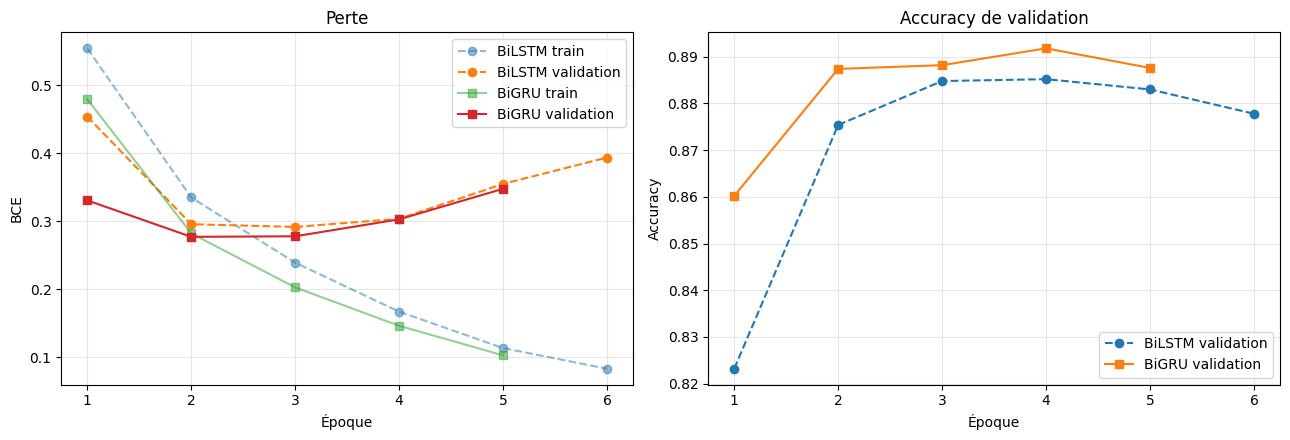

BiLSTM : vrais négatifs 2228 | faux positifs 272 | faux négatifs 303 | vrais positifs 2197
BiGRU : vrais négatifs 2198 | faux positifs 302 | faux négatifs 223 | vrais positifs 2277


In [12]:
rows = []
for name, m in [("BiLSTM", m_lstm), ("BiGRU", m_gru)]:
    rows.append({"Modèle": name, "Accuracy": m["accuracy"], "Precision": m["precision"], "Recall": m["recall"],
                 "F1": m["f1"], "F1 macro": m["f1_macro"], "Meilleure époque": m["best_epoch"],
                 "Temps (s)": m["train_time_s"], "Paramètres": m["n_parameters"]})
results_table = pd.DataFrame(rows).set_index("Modèle")
display(results_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, hist, style in [("BiLSTM", hist_lstm, "o--"), ("BiGRU", hist_gru, "s-")]:
    axes[0].plot(range(1, len(hist["val_loss"]) + 1), hist["train_loss"], style, alpha=0.5, label=f"{name} train")
    axes[0].plot(range(1, len(hist["val_loss"]) + 1), hist["val_loss"], style, label=f"{name} validation")
    axes[1].plot(range(1, len(hist["val_acc"]) + 1), hist["val_acc"], style, label=f"{name} validation")
axes[0].set(title="Perte", xlabel="Époque", ylabel="BCE")
axes[1].set(title="Accuracy de validation", xlabel="Époque", ylabel="Accuracy")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "lstm_gru_curves.png"), dpi=130)
plt.show()

for name, m in [("BiLSTM", m_lstm), ("BiGRU", m_gru)]:
    (tn, fp), (fn, tp) = m["confusion_matrix"]
    print(f"{name} : vrais négatifs {tn} | faux positifs {fp} | faux négatifs {fn} | vrais positifs {tp}")

## 8. Analyse des erreurs

Avis mal classés par le meilleur des deux modèles, avec la probabilité « positif » prédite.

In [13]:
best_name, best_preds, best_probs = (
    ("BiLSTM", preds_lstm, probs_lstm) if m_lstm["accuracy"] >= m_gru["accuracy"] else ("BiGRU", preds_gru, probs_gru)
)
errors = test_df.assign(pred=best_preds, proba_positive=best_probs)
errors = errors[errors["pred"] != errors["label"]]
print(f"Modèle analysé : {best_name} | {len(errors)} erreurs sur {len(test_df)} avis de test\n")
for _, row in errors.sample(6, random_state=SEED).iterrows():
    truth = "positif" if row["label"] == 1 else "négatif"
    text = row["review"].replace("<br />", " ")
    print(f"[vrai : {truth} | P(positif) = {row['proba_positive']:.2f}] {text[:260]}...\n")

Modèle analysé : BiGRU | 525 erreurs sur 5000 avis de test

[vrai : négatif | P(positif) = 0.52] Last night, I attended a screening of Badland with my cousin. We were kind of excited to learn once we got there that the director/writer, the producer (his wife), and several cast members were also in attendance and that there would be a discussion and Q&A af...

[vrai : négatif | P(positif) = 0.61] Dane tries to hard and is to extreme with all of his yelling and going crazy, spilling water on himself and rolling on the floor. To much. Calm down, get yourself together and make us laugh. I didn't quite understand his comparison toward comics and rock stars...

[vrai : positif | P(positif) = 0.38] Gordon Parks, the prolific black Life magazine photographer, made a true ticking-timebomb of a movie here - one that does not mess around! Based upon the true story of two NYC cops - later dubbed Batman and Robin - who singlehandedly employed radical tactics t...

[vrai : positif | P(positif) = 0.1

In [14]:
def predict_sentiment(text, model):
    model.eval()
    X, L = encode([preprocess(text)])
    with torch.no_grad():
        p = torch.sigmoid(model(X.to(device), L)).item()
    return ("positif" if p > 0.5 else "négatif"), p


for sentence in ["This movie was an absolute masterpiece. I loved every second!",
                 "A boring, predictable mess. I wanted my money back."]:
    label, p = predict_sentiment(sentence, model_lstm)
    print(f"{label} ({p:.3f}) <- {sentence}")

positif (0.981) <- This movie was an absolute masterpiece. I loved every second!
négatif (0.013) <- A boring, predictable mess. I wanted my money back.


## 9. Sauvegarde des résultats

In [15]:
payload = {
    "task": "IMDB sentiment, BiLSTM vs BiGRU (GloVe 100d)",
    "split": {"train": len(train_df), "val": len(val_df), "test": len(test_df), "seed": SEED,
              "test_fingerprint": SPLIT_FINGERPRINT},
    "config": {"max_len": MAX_LEN, "min_freq": MIN_FREQ, "vocab_size": len(vocab), "embed_dim": EMBED_DIM,
               "hidden": HIDDEN, "dropout": DROPOUT, "lr": LR, "weight_decay": WEIGHT_DECAY,
               "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE},
    "environment": {"device": str(device), "torch": torch.__version__, "python": platform.python_version(),
                    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None},
    "models": {"bilstm": m_lstm, "bigru": m_gru},
    "history": {"bilstm": hist_lstm, "bigru": hist_gru},
}
out_path = os.path.join(RESULTS_DIR, "lstm_gru_metrics.json")
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(payload, f, indent=2, ensure_ascii=False)
print("Résultats enregistrés :", out_path)

try:  # téléchargement automatique dans Colab
    from google.colab import files
    files.download(out_path)
    files.download(os.path.join(RESULTS_DIR, "lstm_gru_curves.png"))
except ImportError:
    pass

Résultats enregistrés : results/lstm_gru_metrics.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>